# BERTopic Analysis Pipeline

This notebook runs the complete BERTopic analysis pipeline.

In [3]:
import json
import os
import glob
import pandas as pd
import numpy as np
from bertopic import BERTopic
from IPython.display import Image, display

## 1. Encode Embeddings

In [2]:
!python3 ../scripts/encode_embeddings.py

Loading data from data/data.csv...
Loading sentence transformer model: sentence-transformers/paraphrase-multilingual-mpnet-base-v2...
Encoding sentences...
Batches: 100%|██████████████████████████████████| 34/34 [00:05<00:00,  6.53it/s]
Saving embeddings to ../embeddings/embeddings.npy...
Saving index to ../embeddings/index.csv...
Encoding complete.


## 2. Grid Search & Bootstrap Stability Analysis

Run grid search with bootstrap stability analysis. This will create a comprehensive figure showing all quality metrics.

In [3]:
!python3 ../scripts/grid_search.py

Loading data...
Grid Search: 100%|██████████████████████████████| 27/27 [25:37<00:00, 56.94s/it]
Bootstrap stability analysis complete. Results saved to ../results/stability/metrics.json

Creating grid search metrics visualization...
Saved grid search visualization to: ../results/Figures/gridsearch_metrics.png

✓ Review the generated figure: ../results/Figures/gridsearch_metrics.png
✓ Use these results to manually select your preferred configuration in the notebook.


## 3. Review Grid Search Results

Review the generated figure to understand the quality metrics across different hyperparameter configurations.

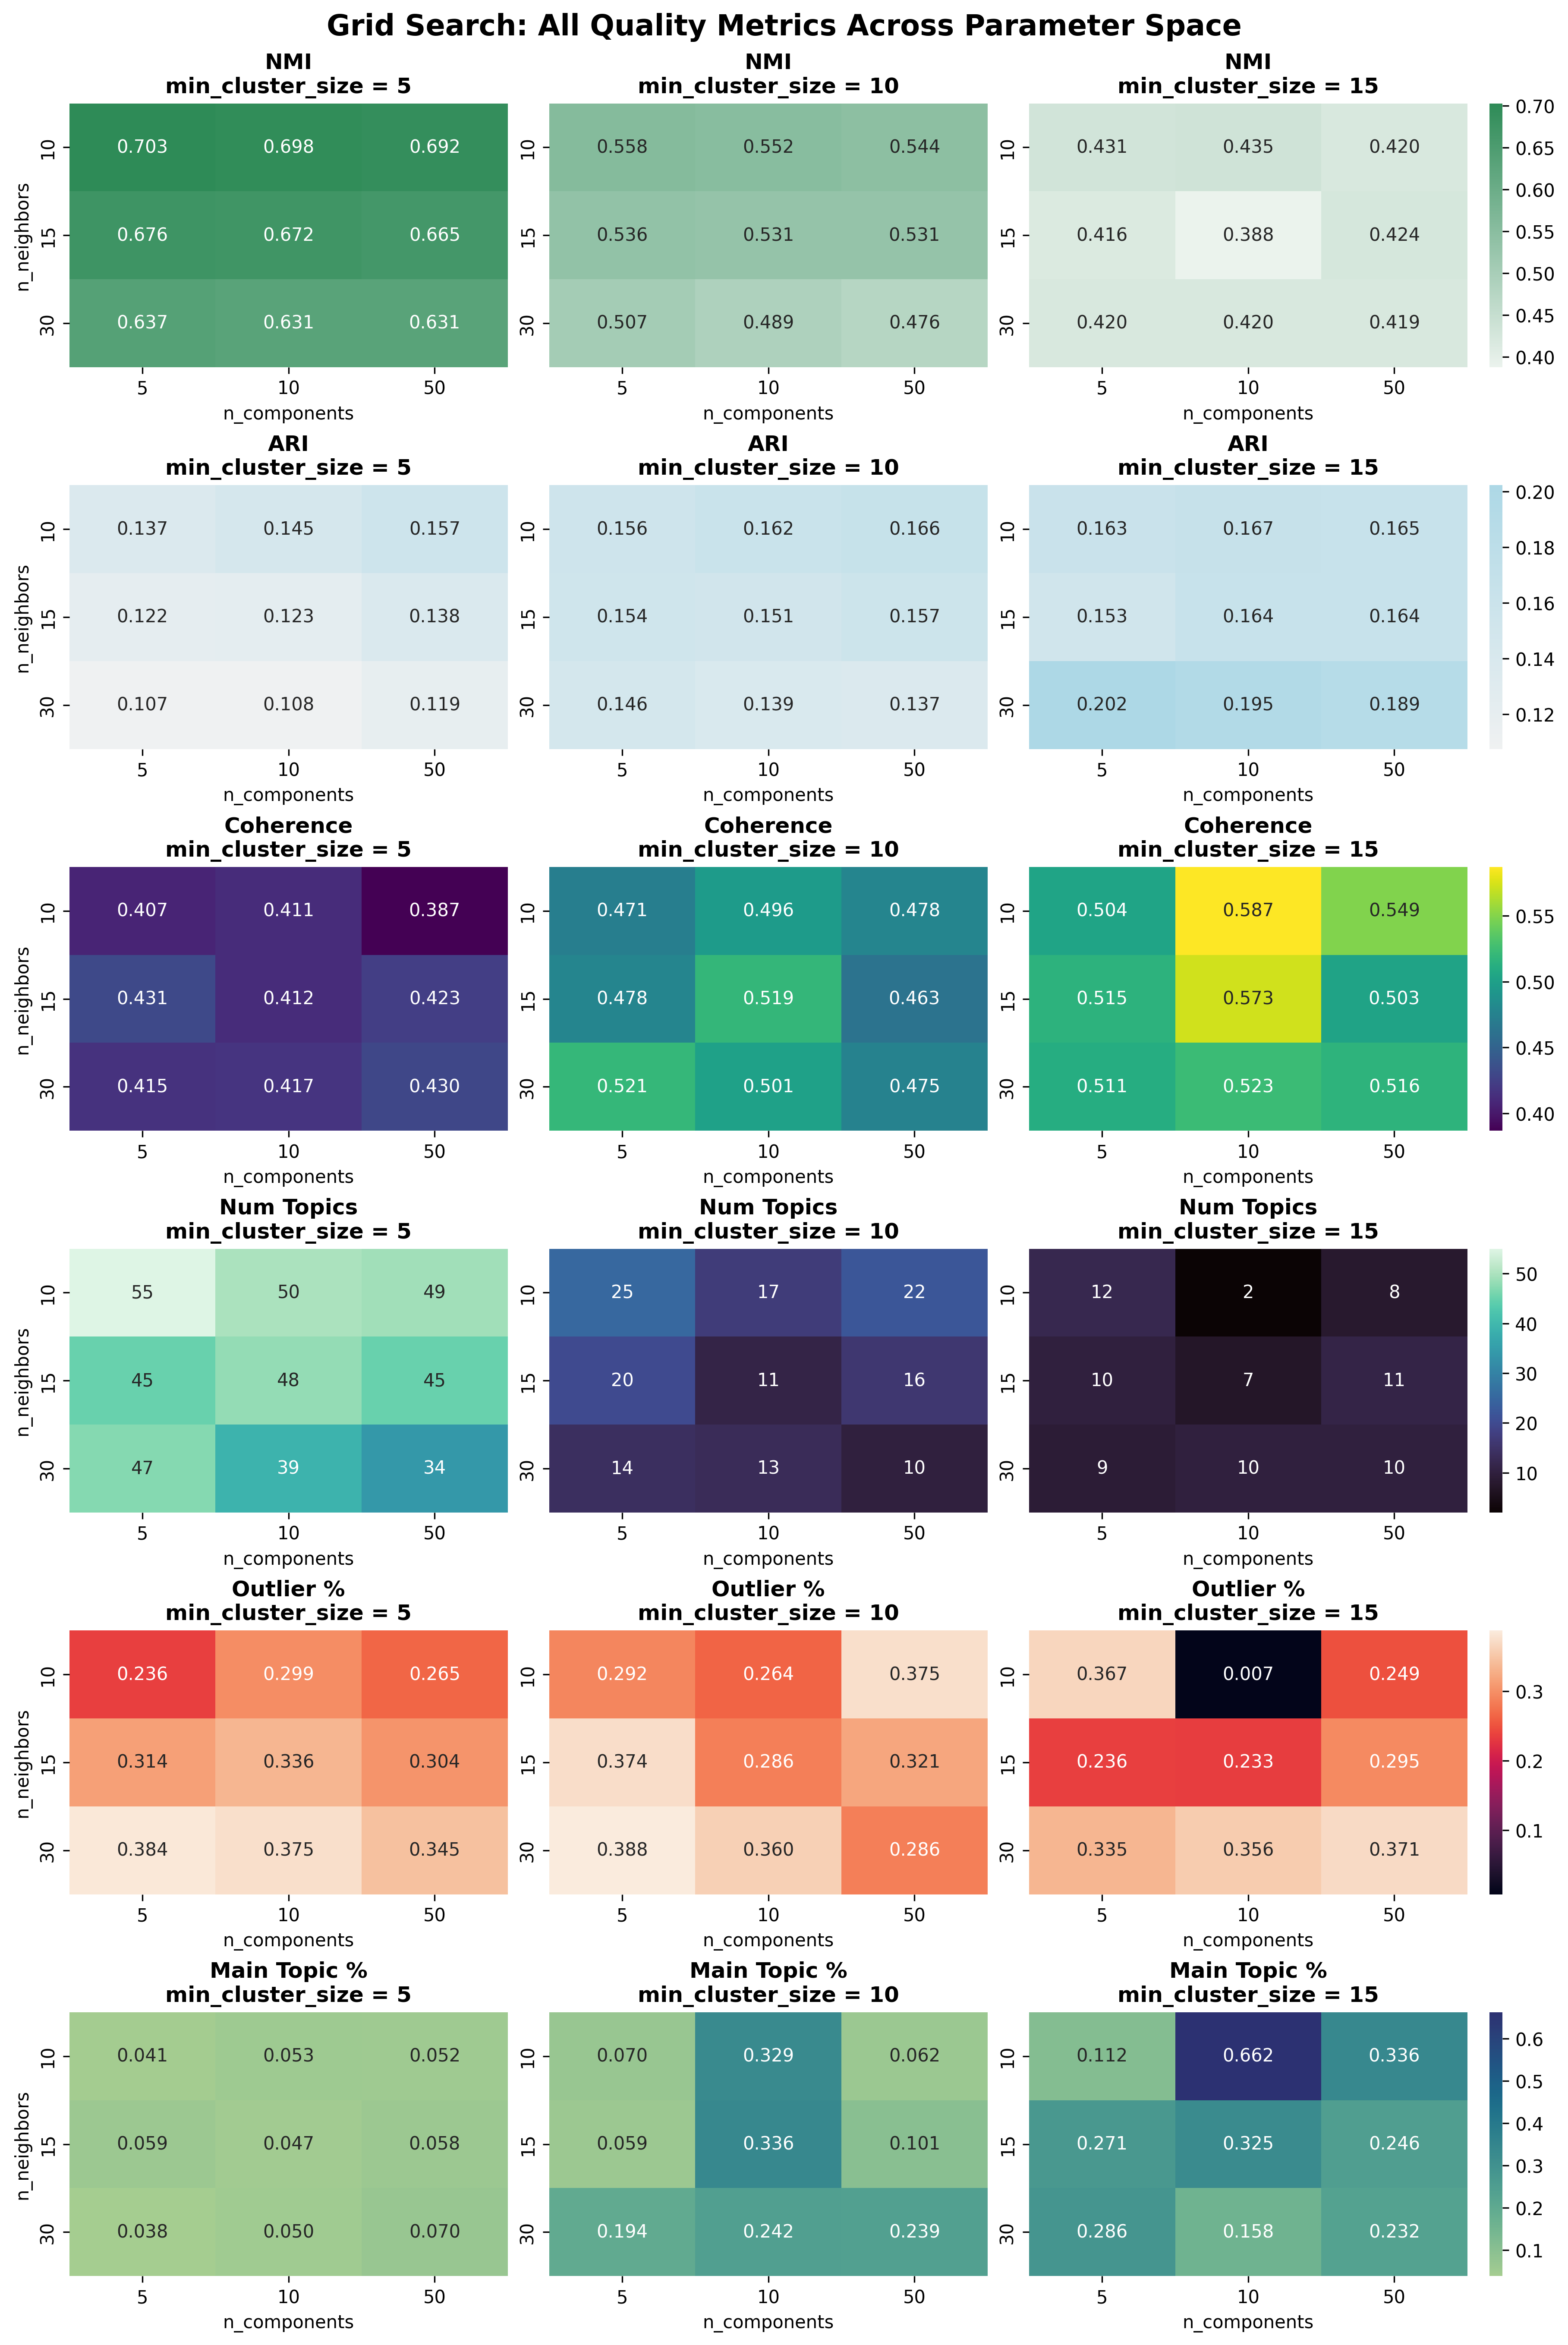

In [4]:
# Display the grid search results figure
fig_path = '../results/Figures/gridsearch_metrics.png'
if os.path.exists(fig_path):
    display(Image(filename=fig_path, width=1200))
else:
    print("Figure not found. Please run the grid search first.")

## 4. Manual Model Selection

Based on the figure above, select your preferred configuration considering:
- **NMI/ARI**: Stability across bootstrap samples (higher is better)
- **Coherence**: Topic quality and interpretability (higher is better)
- **Num Topics**: Number of discovered topics
- **Outlier %**: Fraction of documents not assigned to topics (lower is better)
- **Main Topic %**: Size of the largest topic (balance needed)

Create your selection below:

In [5]:
# Modify these values based on your preferred configuration from the grid search figure above
selected_config = {
    "umap__n_neighbors": 15,  # Update with your choice
    "umap__n_components": 10,  # Update with your choice
    "hdbscan__min_cluster_size": 15,  # Update with your choice
    "selection_rationale": "Highest coherence not collapsed to 2 clusters" # Update with your rationale
}

# Save selection
os.makedirs("../results/selection", exist_ok=True)
with open("../results/selection/best_model_config.json", 'w') as f:
    json.dump(selected_config, f, indent=4)

print("✓ Selected configuration saved to ../results/selection/best_model_config.json")
print(json.dumps(selected_config, indent=2))

✓ Selected configuration saved to ../results/selection/best_model_config.json
{
  "umap__n_neighbors": 15,
  "umap__n_components": 10,
  "hdbscan__min_cluster_size": 15,
  "selection_rationale": "Highest coherence not collapsed to 2 clusters"
}


## 5. Fit Final Model and Extract Topics

Fit the final BERTopic model with your selected configuration and extract topic information.

In [6]:
!python3 ../scripts/fit_final_model.py

Loading selected model configuration...

Selected configuration:
  n_neighbors: 15
  n_components: 10
  min_cluster_size: 15
  Rationale: Highest coherence not collapsed to 2 clusters

Loading data...

Fitting BERTopic model...
Number of topics discovered: 7

Extracting topic information...
Saved topic details to: ../results/final_model_v20251128_135307/topic_details.csv

Creating document assignments...
Saved document assignments to: ../results/final_model_v20251128_135307/document_topic_assignments.csv

Creating topic visualization with datamapplot...
✓ Saved topic visualization to: ../results/final_model_v20251128_135307/topic_map.png

Saving fitted model...
2025-11-28 13:53:20,422 - BERTopic - WARNING: When you use `pickle` to save/load a BERTopic model,please make sure that the environments in which you saveand load the model are **exactly** the same. The version of BERTopic,its dependencies, and python need to remain the same.
✓ Saved model to: ../results/final_model_v20251128_13

## 6. Topic Labeling (Optional)

Examine the generated files in your latest model directory:
- `topic_details.csv` - Top words and representative documents for each topic
- `document_topic_assignments.csv` - Document assignments to topics

Then assign meaningful labels below and regenerate the visualization.

In [1]:
# Assign custom labels based on your interpretation of the topics

labels = {
    -1: "Outliers",
    0: "0 - General disease knowledge, health fears, and taboos",
    1: "1 - General vaccination importance",
    2: "2 - Trusted sources of health information",
    3: "3 - Personal experiences with vaccination",
    4: "4 - Private vs Public sector debate",
    5: "5 - COVID-19 vaccine adverse effects",
    6: "6 - Erosion of institutional trust post pandemic",
    # Add more topics as needed
}

print("Custom labels:")
for topic_id, label in labels.items():
    if topic_id != -1:
        print(f"  Topic {topic_id}: {label}")

Custom labels:
  Topic 0: 0 - General disease knowledge, health fears, and taboos
  Topic 1: 1 - General vaccination importance
  Topic 2: 2 - Trusted sources of health information
  Topic 3: 3 - Personal experiences with vaccination
  Topic 4: 4 - Private vs Public sector debate
  Topic 5: 5 - COVID-19 vaccine adverse effects
  Topic 6: 6 - Erosion of institutional trust post pandemic


### Generate Labeled Visualization

Loading model from: ../results/final_model_v20251128_135307
✓ Model loaded
Creating labeled visualization...
✓ Saved labeled visualization to: ../results/final_model_v20251128_135307/topic_map_labeled.png


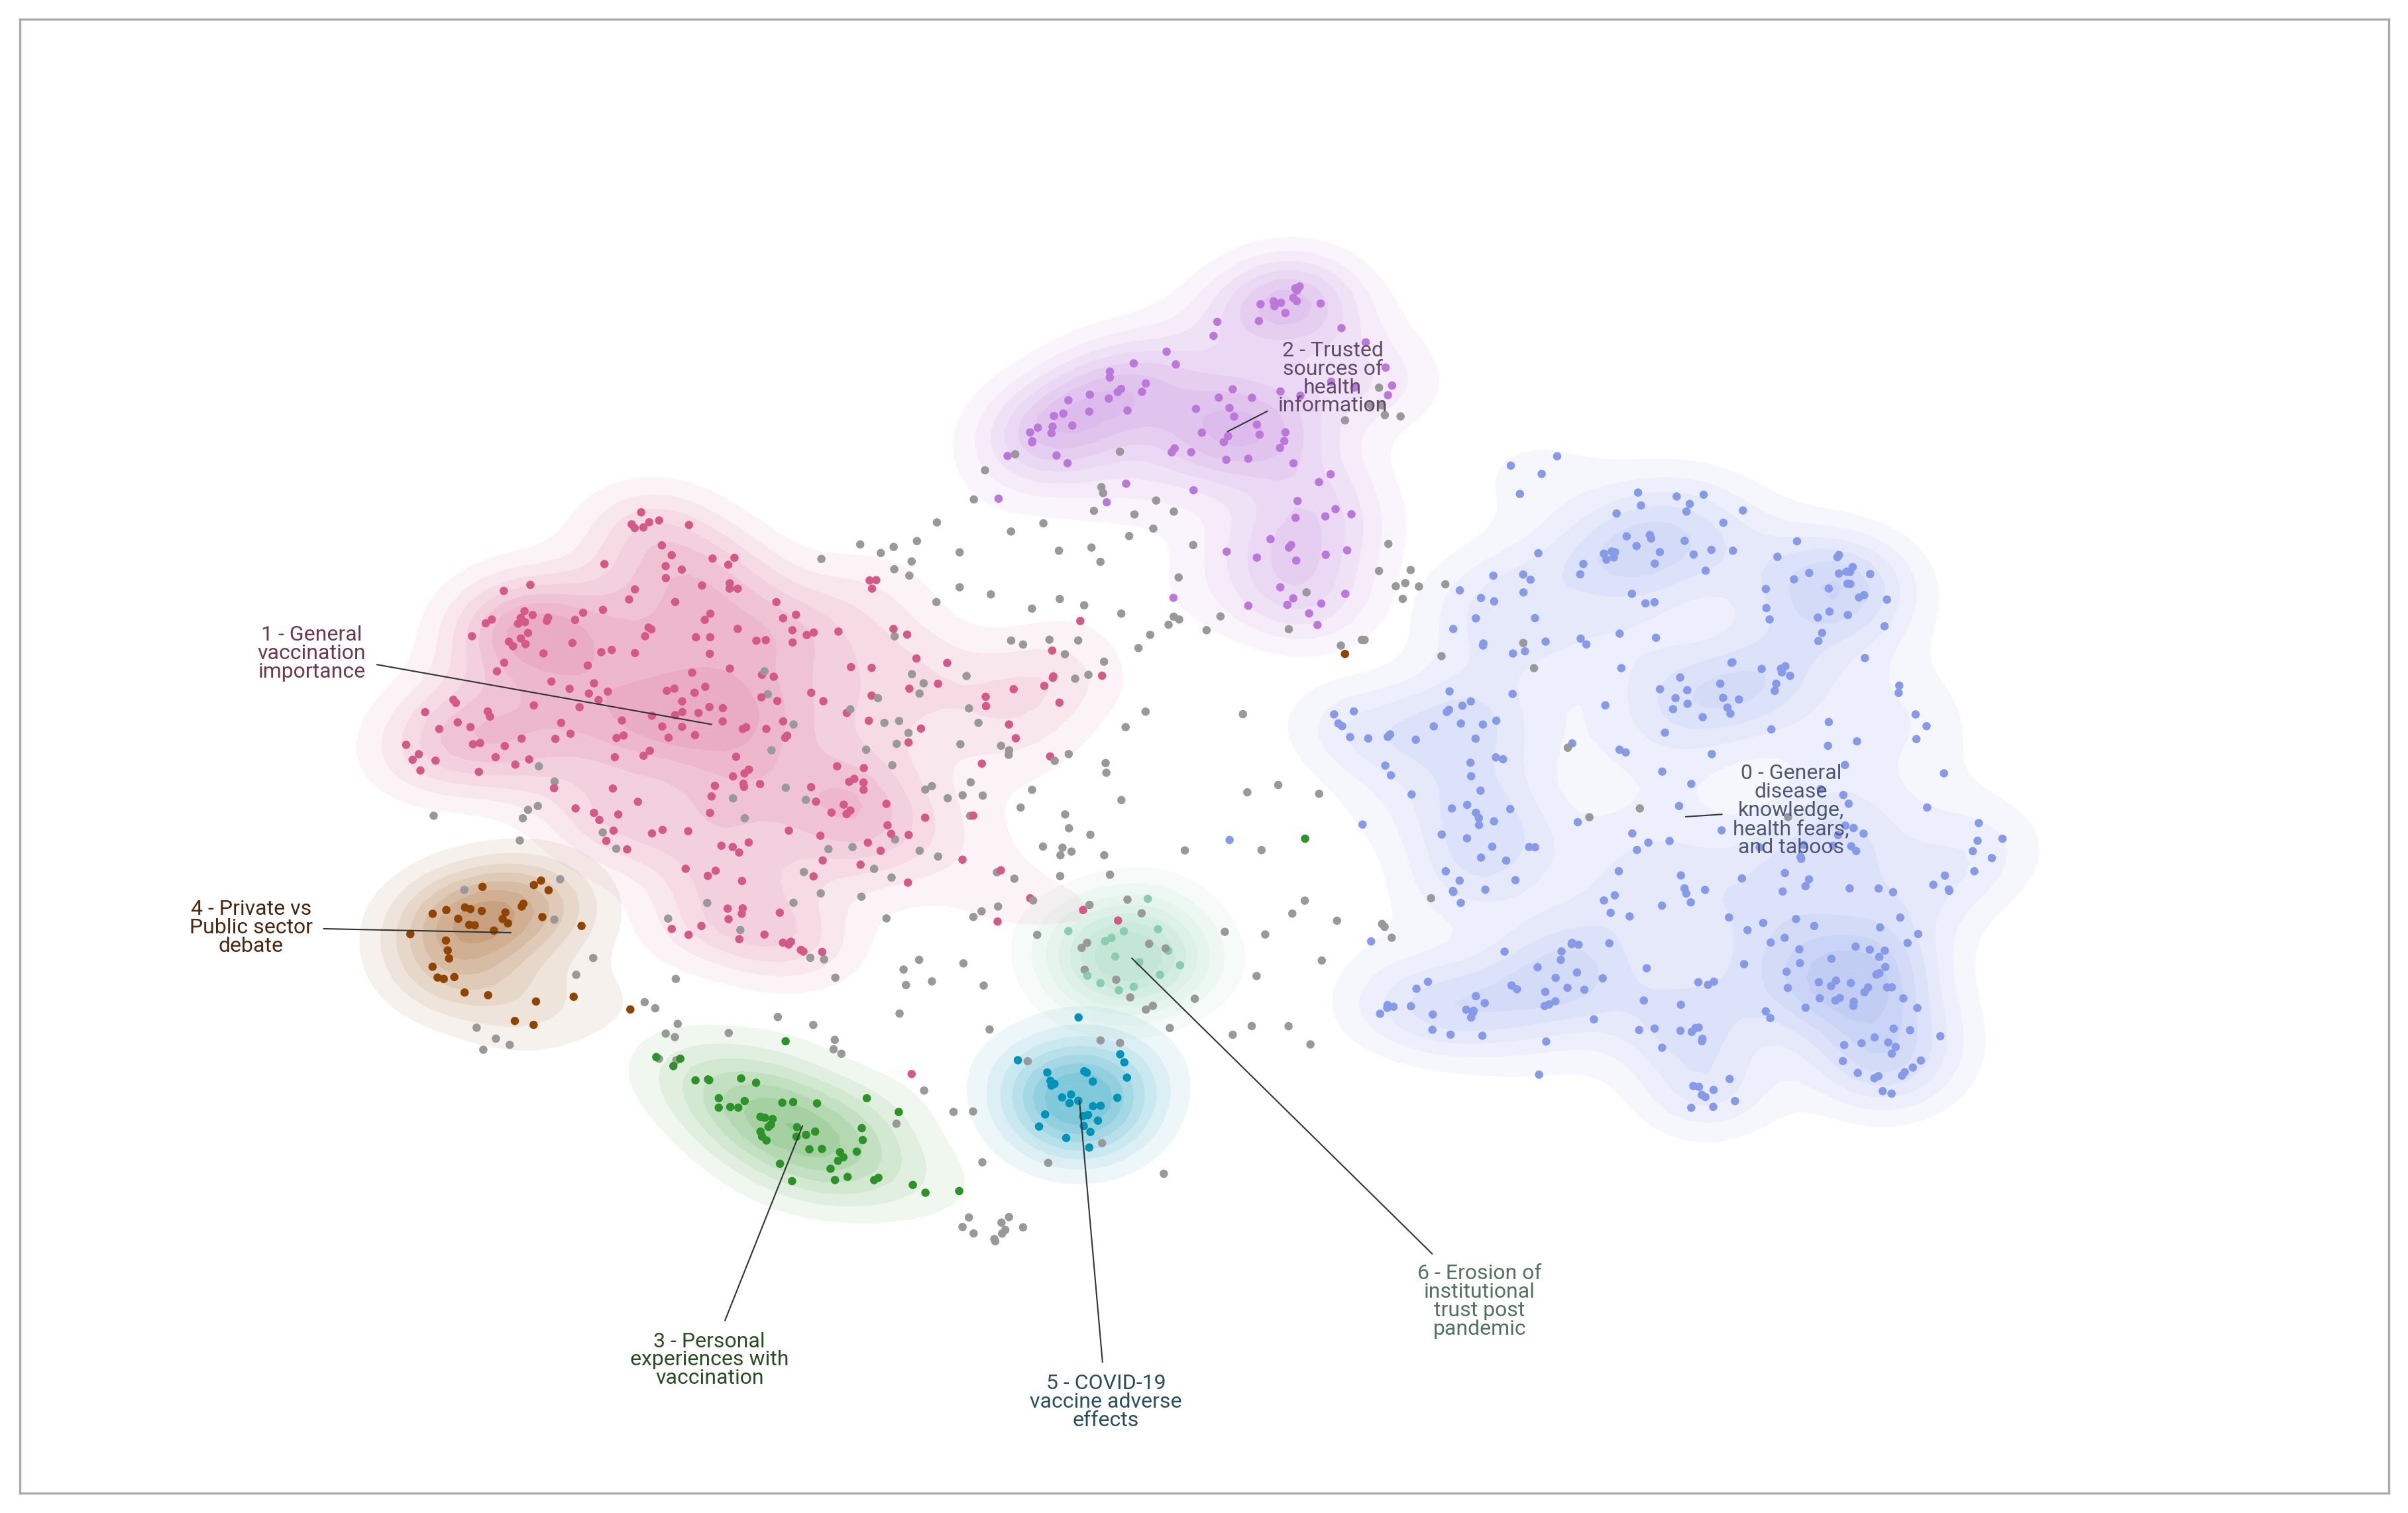

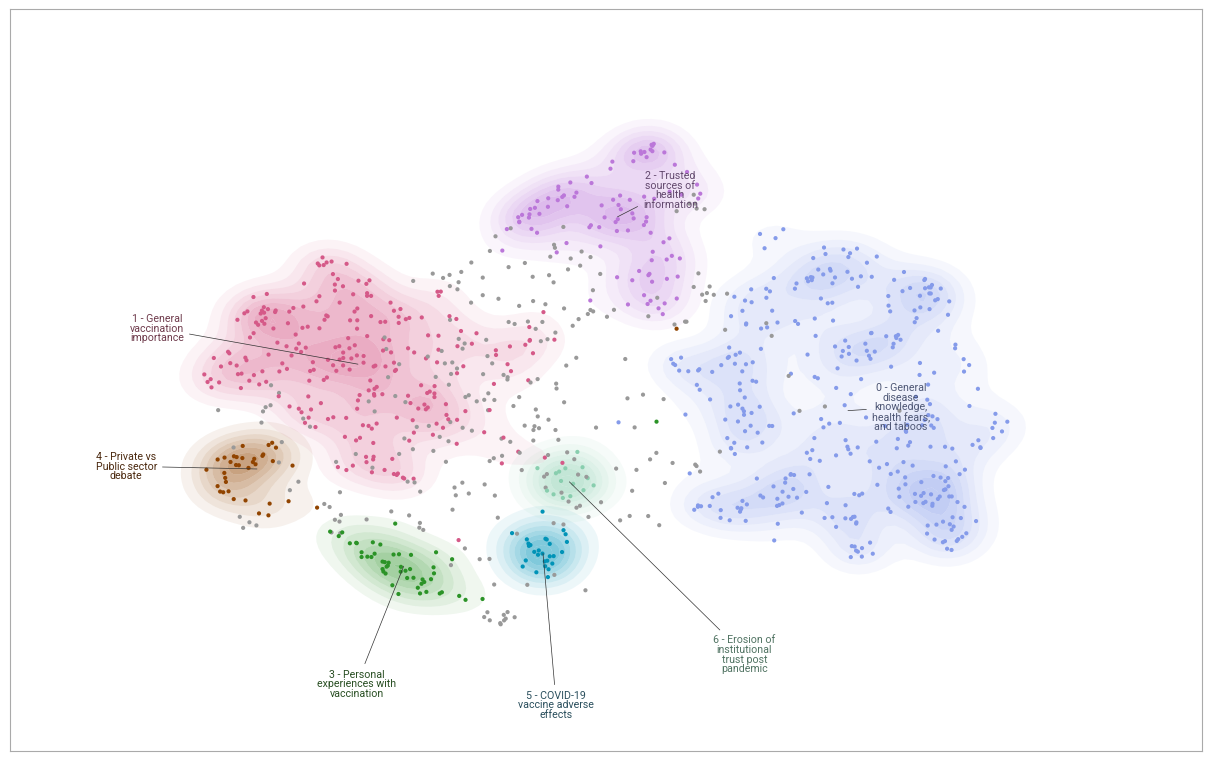

In [4]:
# Generate visualization with custom labels

# Find the most recent final model directory
model_dirs = glob.glob("../results/final_model_v*")
if not model_dirs:
    print("No final model directory found. Please run Section 5 first.")
else:
    latest_model = max(model_dirs)
    print(f"Loading model from: {latest_model}")
    
    # Load the saved model
    model_path = f"{latest_model}/topic_model"
    topic_model = BERTopic.load(model_path)
    print("✓ Model loaded")
    
    # Load data and embeddings (same as used in fit_final_model.py)
    df = pd.read_csv("../data/data.csv")
    embeddings = np.load("../embeddings/embeddings.npy")
    docs = df['sentence'].tolist()
    
    # Set custom labels on the model
    topic_model.set_topic_labels(labels)
    
    # Create visualization with custom labels (same approach as fit_final_model.py)
    print("Creating labeled visualization...")
    fig = topic_model.visualize_document_datamap(
        docs, 
        embeddings=embeddings,  # Same embeddings used to fit the model
        custom_labels=True,
        title=""
    )
    
    # Save the labeled visualization
    labeled_viz_path = f"{latest_model}/topic_map_labeled.png"
    fig.savefig(labeled_viz_path, dpi=300, bbox_inches='tight')
    print(f"✓ Saved labeled visualization to: {labeled_viz_path}")
    
    # Display
    display(Image(filename=labeled_viz_path, width=1000))